# 현실의 데이터 26: 흉부 X-ray 폐렴 찾기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/26_medical.ipynb)

**분야**: 이미지 · 소리 · 3D &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 의료 영상 · 진단 보조 · 놓치면 안 되는 문제

> X-ray 사진 한 장에서 폐렴을 찾을 수 있을까?

**데이터**: MedMNIST · PneumoniaMNIST (약 4MB). Yang et al. (2023). 소아 흉부 X-ray 5,856장을 28×28 로 줄인 판 (학습 4,708 · 검증 524 · 시험 624), 정상 / 폐렴. Hugging Face 사본에서 받는다.

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | X-ray 사진 한 장 (28×28) |
| ② 입력 X | 흑백 픽셀 784개 |
| ③ 출력 y | 정상 0 / 폐렴 1 |
| ④ 평가지표 | 재현율 (놓친 환자) · ROC-AUC |
| ⑤ 기준선 | 가장 흔한 쪽 (폐렴) |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Yang et al. (2023) MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification, Scientific Data](https://arxiv.org/abs/2110.14795)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://huggingface.co/datasets/albertvillanova/medmnist-v2/resolve/main/data/pneumoniamnist.npz"
z = np.load(download(URL, "data/pneumoniamnist.npz"))
Xtr, ytr = z["train_images"], z["train_labels"].ravel()
Xte, yte = z["test_images"], z["test_labels"].ravel()
print(Xtr.shape, Xte.shape, Xtr.dtype, Xtr.min(), Xtr.max())
print(f"pneumonia share: train {ytr.mean():.1%}, test {yte.mean():.1%}")

(4708, 28, 28) (624, 28, 28) uint8 0 255
pneumonia share: train 74.2%, test 62.5%


## 열어 보기

정상 · 폐렴 사진을 몇 장씩. 28×28 로 줄였는데도 차이가 보일까? 두 무리의 '평균 사진' 도 그려 보자.

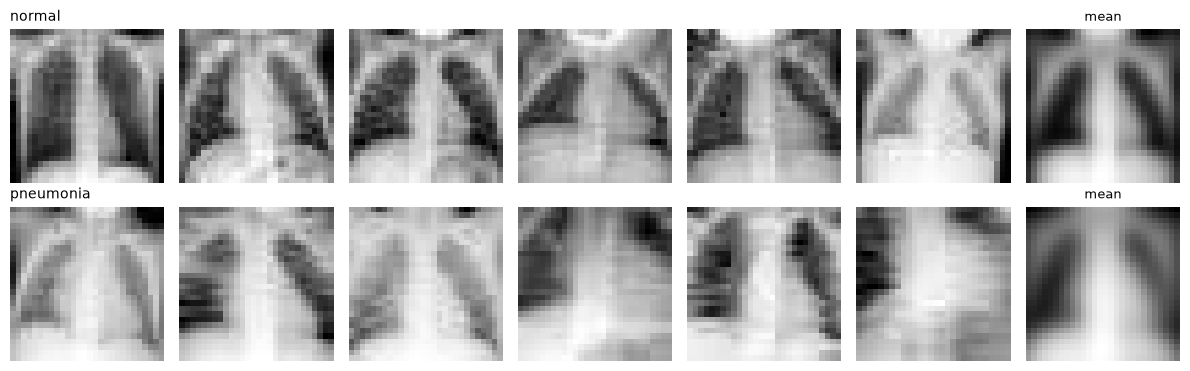

In [3]:
fig, axs = plt.subplots(2, 7, figsize=(12, 3.8))
for r, lab in enumerate([0, 1]):
    idx = np.where(ytr == lab)[0][:6]
    for c, i in enumerate(idx):
        axs[r, c].imshow(Xtr[i], cmap="gray"); axs[r, c].axis("off")
    axs[r, 6].imshow(Xtr[ytr == lab].mean(0), cmap="gray"); axs[r, 6].axis("off"); axs[r, 6].set_title("mean", fontsize=9)
    axs[r, 0].set_title(["normal", "pneumonia"][lab], fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 사진 → 폐렴일까

픽셀 784개를 ÷255 로 맞추고 (1주 3차시) 로지스틱회귀. 기준선 = 전부 '폐렴'. 의료에서는 **놓친 환자** (재현율) 가 특히 중요하다.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

A, B = Xtr.reshape(len(Xtr), -1) / 255, Xte.reshape(len(Xte), -1) / 255
m = LogisticRegression(C=0.1, max_iter=3000).fit(A, ytr)
score = m.predict_proba(B)[:, 1]
for name, pred in [("always pneumonia", np.ones(len(yte), dtype=int)), ("logistic (threshold 0.5)", (score > 0.5).astype(int)),
                   ("logistic (threshold 0.9)", (score > 0.9).astype(int))]:
    p, r = precision_recall(yte, pred)
    print(f"{name:26s} accuracy {np.mean(pred == yte):.1%}  precision {p:.0%}  recall {r:.0%}")
print(f"ROC-AUC {roc_auc_score(yte, score):.2f}")

always pneumonia           accuracy 62.5%  precision 62%  recall 100%
logistic (threshold 0.5)   accuracy 82.9%  precision 79%  recall 98%
logistic (threshold 0.9)   accuracy 85.3%  precision 89%  recall 87%
ROC-AUC 0.92


**관찰**: 기준을 올리면 '폐렴' 이라고 하는 사진이 줄어 정밀도는 오르고 재현율은 떨어진다. 병원에서는 놓친 환자의 비용이 커서 보통 재현율을 높게 잡는다.

## 다른 문제로 바꿔 보기

- 같은 사람의 사진이 학습 · 시험 양쪽에 있으면? 의료 데이터는 **환자 단위** 로 나눠야 한다.
- 사진 크기를 28×28 에서 224×224 로 키우면 (MedMNIST+) 무엇이 좋아지고 무엇이 비싸질까?
- 모델이 사진의 '병원 표시 글자' 나 '촬영 기계' 차이를 보고 맞히는 건 아닐까? (지름길 학습)

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |